title: "Generalized linear models (GLMs)"
output: html_document
date: "2022-10-25"

In [5]:
library(tidyverse)

-- Attaching core tidyverse packages ------------------------ tidyverse 2.0.0 --
v dplyr     1.1.4     v readr     2.1.5
v forcats   1.0.1     v stringr   1.5.2
v ggplot2   4.0.0     v tibble    3.3.0
v lubridate 1.9.4     v tidyr     1.3.1
v purrr     1.1.0     
-- Conflicts ------------------------------------------ tidyverse_conflicts() --
x dplyr::filter() masks stats::filter()
x dplyr::lag()    masks stats::lag()
i Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


The goal of this tutorial is to illustrate how GLMs may overcome simpler linear models. We will start with a linear model and improve it with Poisson regression. This type of model will further be refined with non-linear terms. You will also practice comparing models again to find the best model settings.

## The task of Phillippines household size prediction

The dataset is known to you from the lectures. It was collected by the Philippine Statistics Authority in 2015 and contains numerous features including family income and expenditure.
Our data is a subset of approximately 15,000 of the 40,000 observations, focusing on four regions: Central Luzon, Ilocos, Davao, and Visayas. We will focus on the subtask of household size prediction and deal with the limited set of 3 features. The original dataset can be accessed at  https://www.kaggle.com/grosvenpaul/family-income-and-expenditure


In [6]:
data <- read.csv("philippines_households.csv")

# For our purposes, we only need 3 columns
data <- data %>%
  select(Household.Head.Age, Total.Number.of.Family.members, Region)

glimpse(data)

Rows: 15,760
Columns: 3
$ Household.Head.Age             <int> 58, 59, 64, 73, 33, 20, 55, 40, 53, 68,~
$ Total.Number.of.Family.members <int> 3, 3, 2, 1, 6, 4, 8, 2, 4, 7, 5, 2, 1, ~
$ Region                         <chr> "VI - Western Visayas", "VI - Western V~


The following graphs outline the relationship between the age of household head, the region and the household size.


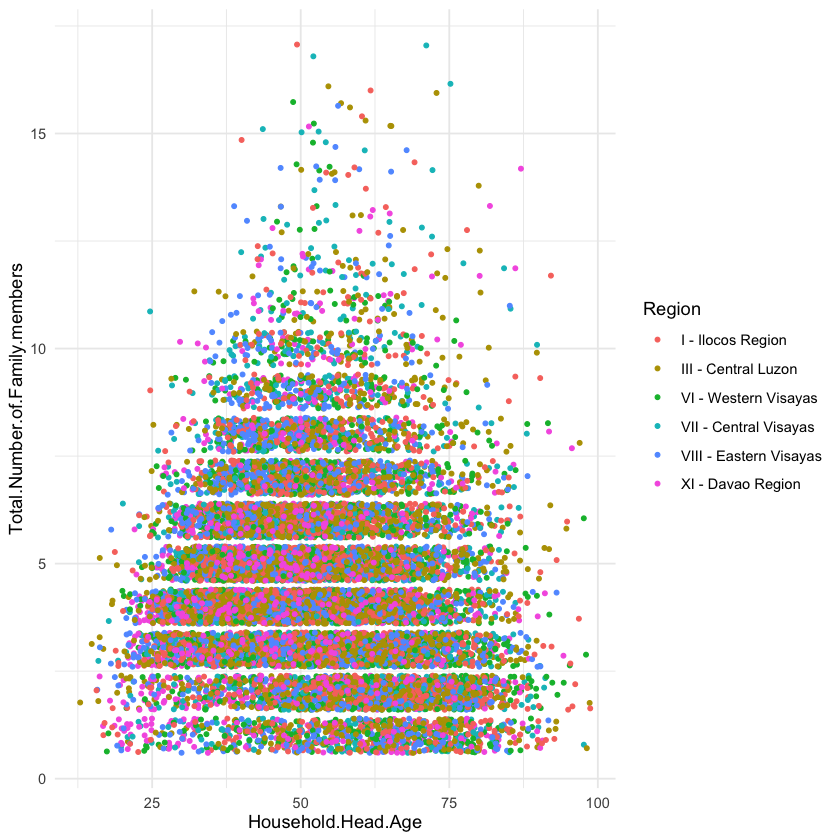

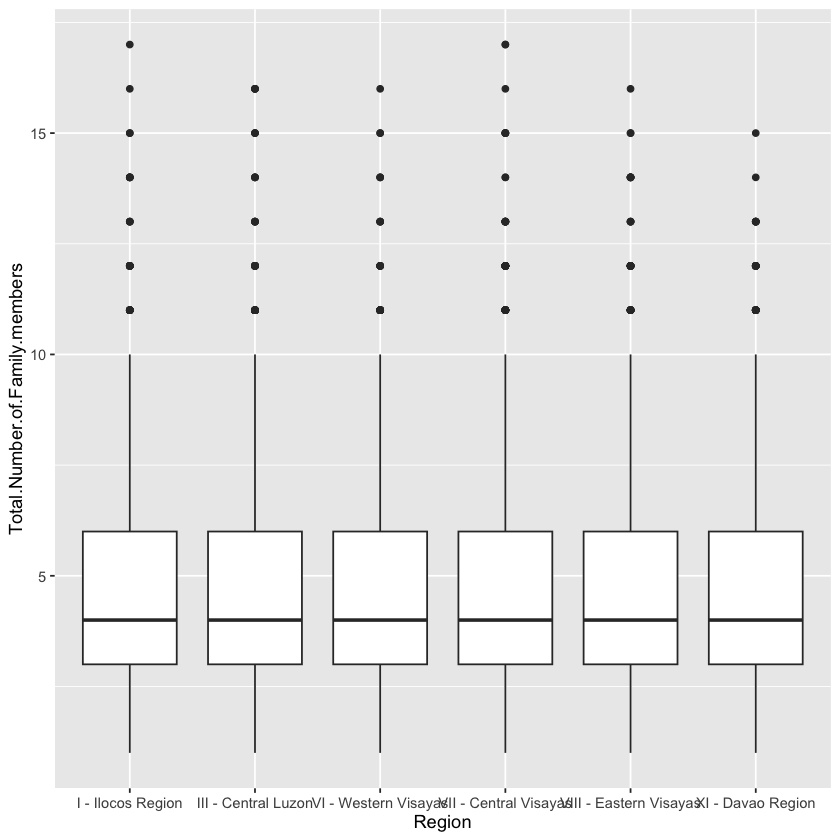

In [7]:
# Visualize the data
data %>% 
  ggplot(aes(x=Household.Head.Age, y=Total.Number.of.Family.members, col=Region)) + 
  geom_jitter(size=1) + 
  theme_minimal()

data %>% 
  ggplot(aes(x=Region, y=Total.Number.of.Family.members)) + 
  geom_boxplot()

## Linear regression

As the first benchmark, let us use a simple linear regression to predict the household size. Knowing the region boxplot above, we will only work with age to explain household size.



Call:
lm(formula = Total.Number.of.Family.members ~ Household.Head.Age, 
    data = data)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.2085 -1.6530 -0.3926  1.3123 12.7289 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)         5.503592   0.068814   79.98   <2e-16 ***
Household.Head.Age -0.017360   0.001261  -13.76   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 2.282 on 15758 degrees of freedom
Multiple R-squared:  0.01188,	Adjusted R-squared:  0.01181 
F-statistic: 189.4 on 1 and 15758 DF,  p-value: < 2.2e-16


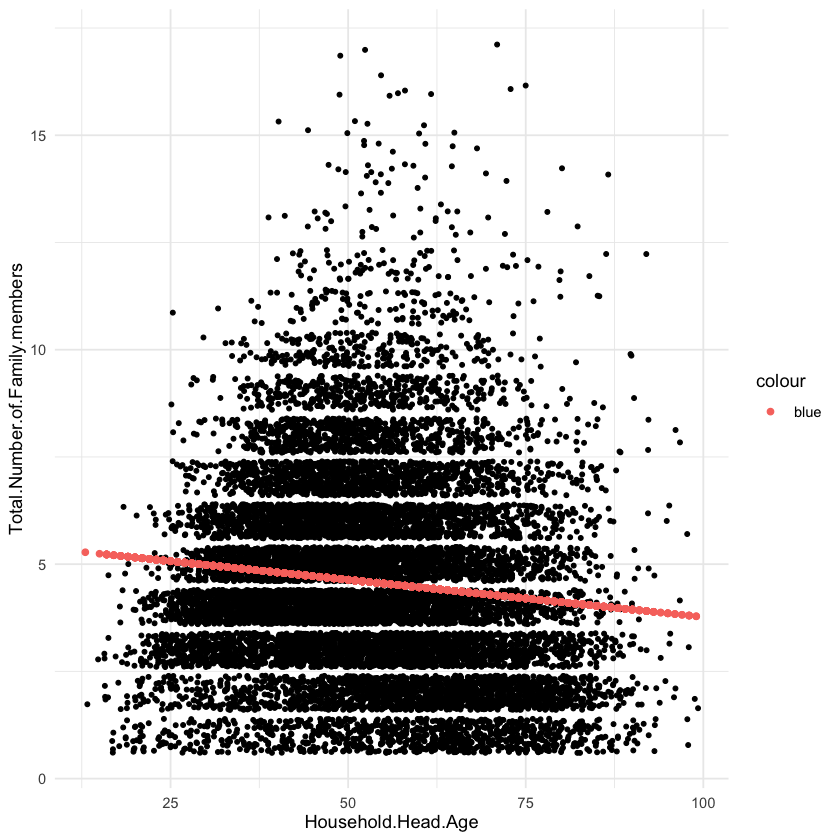

In [8]:
# First, use a simple Linear Regression to predict the family size
linreg <- lm(Total.Number.of.Family.members ~ Household.Head.Age, data=data)
summary(linreg)

preds <- predict(linreg, data)

# Plot the linear regression fit
data %>% 
  mutate(preds=preds) %>%
  ggplot(aes(x=Household.Head.Age, y=Total.Number.of.Family.members)) + 
  geom_jitter(size=1) + 
  geom_point(aes(x=Household.Head.Age, y=preds, col='blue')) +
  # geom_smooth(method = "lm") +
  theme_minimal()


## Poisson regression

Poisson regression works well for count data. Additionally, it assumes that the target variable shows Poisson distribution whose mean and variance change with the dependent variables. As regards the mutual relationship between mean and variance, it should remain approximately equal.


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


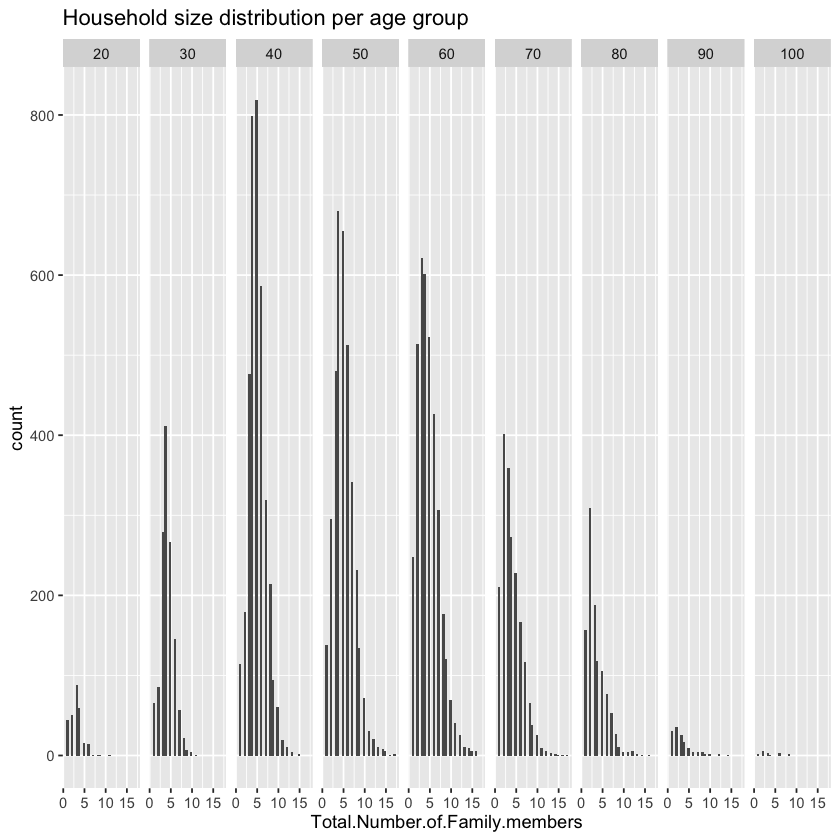

In [9]:
# Assess the applicability of Poisson regression. 
# Slice the data at each age-group and observe the distribution of the count response
bin_size <- 10

data %>%
  mutate(bins = round(Household.Head.Age / bin_size) * bin_size) %>% 
  filter(bins > 10) %>%
  ggplot(aes(x=Total.Number.of.Family.members)) +
  geom_histogram() + facet_grid(cols = vars(bins)) +
  ggtitle("Household size distribution per age group")
  

The household size is obviously a count variable. Despite graphically unclear relationship between household size mean and variance in the individual age groups, we will start with a simple Poisson regression model.



Call:
glm(formula = Total.Number.of.Family.members ~ Household.Head.Age, 
    family = "poisson", data = data)

Coefficients:
                     Estimate Std. Error z value Pr(>|z|)    
(Intercept)         1.7225559  0.0139566  123.42   <2e-16 ***
Household.Head.Age -0.0038036  0.0002595  -14.66   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 17878  on 15759  degrees of freedom
Residual deviance: 17662  on 15758  degrees of freedom
AIC: 69221

Number of Fisher Scoring iterations: 4


`geom_smooth()` using formula = 'y ~ x'


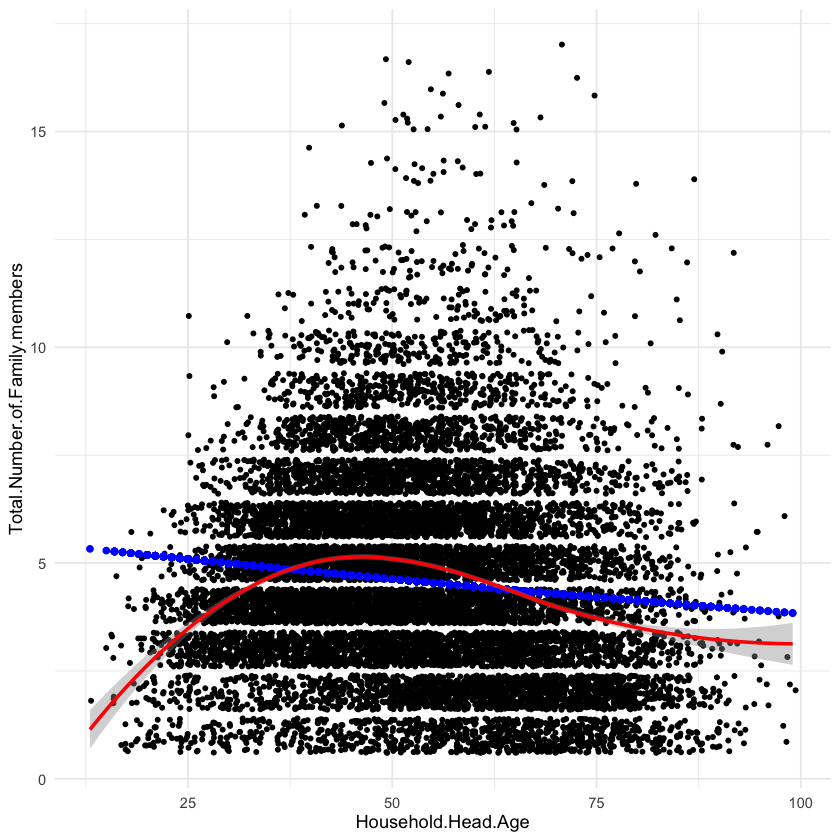

In [12]:
# Let's try the Poisson regression, which should be better suited - we have count data
# and its distribution seem to be Poisson. 
poiss_reg <- glm(Total.Number.of.Family.members ~ Household.Head.Age, family = 'poisson', data=data)
summary(poiss_reg)

# Get the Poisson regression predictions. 
preds <- predict(poiss_reg, data)
# Recall, how to change the linear regression output to the actual response
# TODO add your code here
preds <- exp(preds)

# Use the predictions to plot the Poisson regression fit
# compare with smoothed conditional mean household size
data %>% 
  mutate(preds = preds) %>%
  ggplot(aes(x=Household.Head.Age, y=Total.Number.of.Family.members)) + 
  geom_jitter(size=1) + 
  geom_point(aes(x=Household.Head.Age, y=preds), colour="blue") +
  #geom_smooth(method = 'glm', method.args = list(family = 'poisson')) +
  geom_smooth(method = 'loess', colour="red") +
  theme_minimal()

# Questions> Look at the summary - what is the equation of the model?
#     Knowing the model prescription, think of how can we interpret the coefficients
#       Ask the usual question "How does the output change with a unit increase of the predictor?"

The model obviously improves the null model (Household.Head.Age has a significant coefficient, the residual deviance is smaller than the null deviance). However, the graphical comparison between the real household sizes, their floating averages over the age and model predictions shows that the model does not capture the relationship between age and household size sufficiently. Now, we will compare it with the simple linear regression.


In [14]:
# But how do we compare the performance of the simple and Poisson regression?
# There is no F-score and R2 in the summary of Poisson model. We need to find a common ground!

# Solution: fit the linear regression again, but this time with the glm() function
# TODO decide the glm family for linear model, hint: help(family)
linreg_glm <- glm(Total.Number.of.Family.members ~ Household.Head.Age, family = gaussian(), data=data)
# Compare the coefficients with the lm() output 
summary(linreg_glm)

# Now we can compare the Poisson and Linear regressions. Lower AIC is better.
poiss_reg$aic
linreg_glm$aic

# Note: The models can't be compared through anova() either since they are not nested


Call:
glm(formula = Total.Number.of.Family.members ~ Household.Head.Age, 
    family = gaussian(), data = data)

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)         5.503592   0.068814   79.98   <2e-16 ***
Household.Head.Age -0.017360   0.001261  -13.76   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for gaussian family taken to be 5.206229)

    Null deviance: 83026  on 15759  degrees of freedom
Residual deviance: 82040  on 15758  degrees of freedom
AIC: 70731

Number of Fisher Scoring iterations: 2


[1] 69220.62

[1] 70730.67

In [23]:
library(splines)

Poisson regression (slightly) helps. Let us add more flexibility into our Poisson model.


`geom_smooth()` using formula = 'y ~ x'


[1] 68436.19

[1] 69220.62

[1] 68413.39

[1] 68436.19 68272.51 68272.33 68268.06

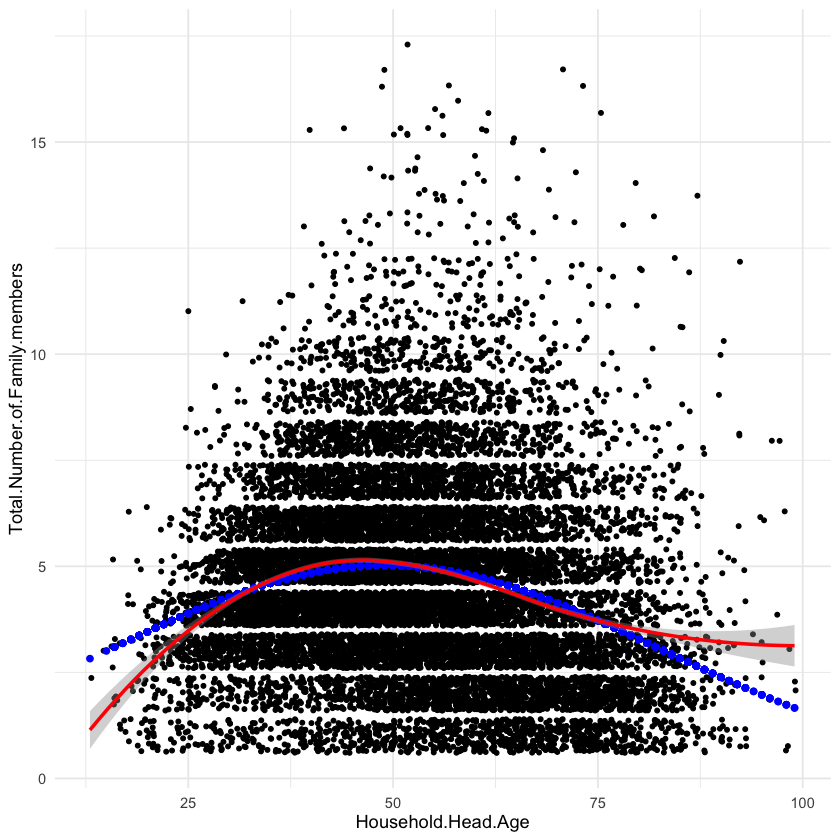

In [25]:
# Look at the data and the first Poisson regression fit.
# TODO put the second order age polynomial into the model
# Do you think the fit needs more flexibility? If yes, see Further questions
poiss_reg2 <- glm(Total.Number.of.Family.members ~ Household.Head.Age, family = 'poisson', data=data)
poiss_reg2 <- glm(Total.Number.of.Family.members ~ Household.Head.Age + I(Household.Head.Age^2), family = 'poisson', data=data)

poiss_reg_region <- glm(Total.Number.of.Family.members ~ poly(Household.Head.Age, 2, raw=TRUE) + Region, 
                        family = 'poisson', data=data)
            
poiss_reg3 <- glm(Total.Number.of.Family.members ~ poly(Household.Head.Age, 3, raw=TRUE), 
                  family = 'poisson', data=data)

poiss_reg4 <- glm(Total.Number.of.Family.members ~ poly(Household.Head.Age, 4, raw=TRUE), 
                  family = 'poisson', data=data)


poiss_reg_spline <- glm(Total.Number.of.Family.members ~ ns(Household.Head.Age, df=4) + Region, 
                        family = 'poisson', data=data)

# Compare AICs

# Make predictions. Care for the correct transformation the outputs
preds2 <- predict(poiss_reg2, data)
preds2 <- exp(preds2)
# preds2 <- predict(poiss_reg2, data, type = "response")

# Use the predictions to plot the Poisson regression fit
# compare with smoothed conditional mean household size
data %>% 
  mutate(preds = preds2) %>%
  ggplot(aes(x=Household.Head.Age, y=Total.Number.of.Family.members)) + 
  geom_jitter(size=1) + 
  geom_point(aes(x=Household.Head.Age, y=preds), colour="blue") +
  geom_smooth(method = 'loess', colour="red") +
  theme_minimal()

# Compare with the simple Poisson
poiss_reg2$aic
poiss_reg$aic
poiss_reg_region$aic


c(poiss_reg2$aic, poiss_reg3$aic, poiss_reg4$aic, poiss_reg_spline$aic)


Obviously, the non-linear term brings further improvement.

##  Further questions: 

1. Show how to refine the model and increase its performance even further. Hint: You may consider other non-linear forms, different link functions and regression types as well as the region feature that has been kept away until now.
2. Compare the models you considered with different criteria and understand how far they match or disagree. Finally, recommend the best model and write a justification for this recommendation.